In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_excel("Online Retail.xlsx")

df.head()

In [ ]:
# Check the number of rows and columns in the dataset
df.shape

# The dataset contains 541,909 rows and 8 columns.

In [ ]:
# Display column names, data types and non-null values
df.info()

In [ ]:
# Generate descriptive statistics for numerical columns
df.describe()

In [ ]:
# Count missing values in each column
df.isna().sum()

In [ ]:
# Count rows that are exact duplicates
df.duplicated().sum()

In [ ]:
# Inspect duplicates,display the first five duplicate rows
df[df.duplicated()].head()

In [11]:
# Remove exact duplicate records
df = df.drop_duplicates()

# Check the updated dataset dimensions
df.shape

(536641, 8)

In [12]:
# Count cancellation transactions
df["InvoiceNo"].astype(str).str.startswith("C").sum()

np.int64(9251)

In [13]:
# Remove cancellation transactions
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

# Check the updated dataset dimensions
df.shape

(527390, 8)

In [14]:
# Count rows with zero or negative quantities
(df["Quantity"] <= 0).sum()

np.int64(1336)

In [15]:
# Remove rows with zero or negative quantities
df = df[df["Quantity"] > 0]

# Check the updated dataset dimensions
df.shape

(526054, 8)

In [16]:
# Count rows with zero or negative prices
(df["UnitPrice"] <= 0).sum()

np.int64(1176)

In [17]:
# Remove rows with zero or negative prices
df = df[df["UnitPrice"] > 0]

# Check the updated dataset dimensions
df.shape

(524878, 8)

In [18]:
# Count missing values in each column
df.isna().sum()

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
dtype: int64

In [21]:
# Calculate sales for each row
df["Sales"] = df["Quantity"] * df["UnitPrice"]

# Display the first five rows, including the Sales column
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [22]:
# Calculate total sales
df["Sales"].sum()

np.float64(10642110.804000001)

In [24]:
# Extract the month from each invoice date
df["Month"] = df["InvoiceDate"].dt.to_period("M")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12


In [25]:
# Add up sales for each month
df.groupby("Month")["Sales"].sum()

Month
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Sales, dtype: float64

In [26]:
# Add up sales for each product and show the top five
df.groupby("Description")["Sales"].sum().sort_values(ascending=False).head(5)

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
Name: Sales, dtype: float64

In [27]:
# Add up sales for each country
df.groupby("Country")["Sales"].sum().sort_values(ascending=False)

Country
United Kingdom          9001744.094
Netherlands              285446.340
EIRE                     283140.520
Germany                  228678.400
France                   209625.370
Australia                138453.810
Spain                     61558.560
Switzerland               57067.600
Belgium                   41196.340
Sweden                    38367.830
Japan                     37416.370
Norway                    36165.440
Portugal                  33683.050
Finland                   22546.080
Singapore                 21279.290
Channel Islands           20440.540
Denmark                   18955.340
Italy                     17483.240
Hong Kong                 15483.000
Cyprus                    13502.850
Austria                   10198.680
Israel                     8129.410
Poland                     7334.650
Greece                     4760.520
Unspecified                4740.940
Iceland                    4310.000
Canada                     3666.380
USA                 

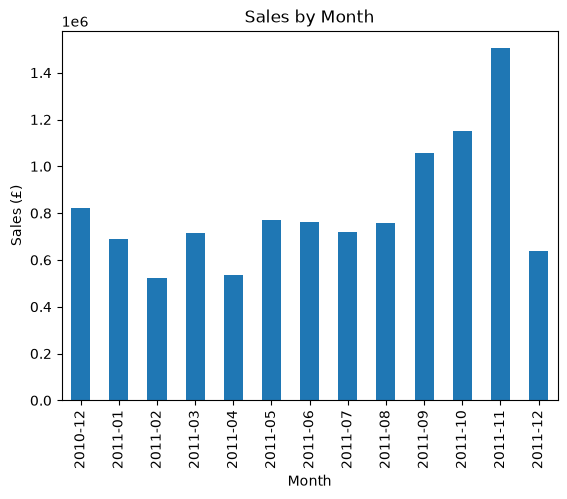

In [28]:
# Create a chart of sales by month
df.groupby("Month")["Sales"].sum().plot(kind="bar")

# Add a title and labels
plt.title("Sales by Month")
plt.xlabel("Month")
plt.ylabel("Sales (£)")
plt.show()

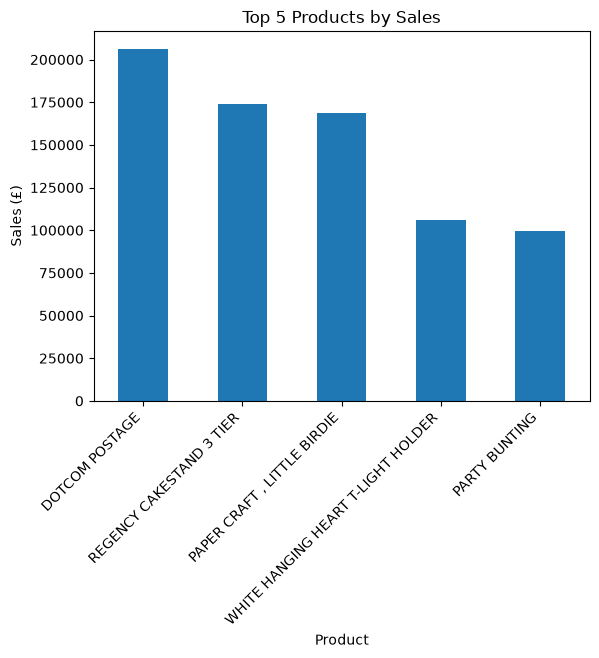

In [29]:
# Calculate sales for each product and keep the top five
top_products = df.groupby("Description")["Sales"].sum().sort_values(ascending=False).head(5)

# Create a bar chart
top_products.plot(kind="bar")

# Add a title and labels
plt.title("Top 5 Products by Sales")
plt.xlabel("Product")
plt.ylabel("Sales (£)")
plt.xticks(rotation=45, ha="right")
plt.show()

In [30]:
#Total sales after cleaning were about £10.64 million.

# DOTCOM POSTAGE had the highest sales, at £206,248.77.

# Sales peaked in November 2011, at about £1.50 million; the United Kingdom contributed the most by country, at about £9.00 million.